# 03. Export features and report usable samples

Select shared usable pixel locations in the fixed and green-up-aligned windows and apply the 20-pixel parcel cap to the shared selection. Lock one train/validation assignment per development parcel group, then finalize the 72 interval predictors and export separate development and reserved external-test packages.


**Input:** Verified windows.json from Preprocessing 02. **Output:** `features.json plus separate development/test features`. **Next:** Training 01.

[Run order and reruns](../../docs/workflow.md).


In [1]:
from pathlib import Path
import sys
import json

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root / "src"))
from crop_pipeline import preprocessing_workflow as workflow
from crop_pipeline.notebook_display import show_table
from crop_pipeline.windows import seasons

window_input = ""  # Optional exact windows.json path from new notebook 02; blank uses its verified pointer.


## Export model inputs

Matched fixed/aligned cohorts retain identical locations. Full cohorts report their own coverage. Budgets are collection targets, not accuracy criteria; unmet budgets and absent crops remain visible. Do not add counts across cohorts.


In [2]:
feature_handoff = workflow.export_features(root, window_input or None)
split_path = feature_handoff.parent / workflow.external.SPLIT_FILENAME
if split_path.is_file():
    print("Locked development parcel assignments:", split_path)
usable_samples = seasons.read_table(feature_handoff.parent / "usable_samples.csv")
for cohort in ("fixed_full", "aligned_full", "fixed_matched", "aligned_matched"):
    show_table([r for r in usable_samples if r["cohort"] == cohort], title=f"Usable samples: {cohort}")


Locked development parcel assignments: ./data/pipeline_work/analysis/external/external_t4tyh93t/development_split.json


Cohort,Partition,Crop,Usable parcel groups,Usable pixels,Target parcels,Target pixels,Parcel shortfall,Pixel shortfall,Budget met
fixed_full,Training,Carrot,284,5254,60,1200,0,0,True
fixed_full,Training,Cabbage,464,9193,60,1200,0,0,True
fixed_full,Training,Potato,384,5322,60,1200,0,0,True
fixed_full,Validation,Carrot,95,1673,20,400,0,0,True
fixed_full,Validation,Cabbage,155,3047,20,400,0,0,True
fixed_full,Validation,Potato,128,1979,20,400,0,0,True
fixed_full,Reserved test,Carrot,45,134,20,400,0,266,False
fixed_full,Reserved test,Cabbage,38,351,20,400,0,49,False
fixed_full,Reserved test,Potato,65,261,20,400,0,139,False


Cohort,Partition,Crop,Usable parcel groups,Usable pixels,Target parcels,Target pixels,Parcel shortfall,Pixel shortfall,Budget met
aligned_full,Training,Carrot,106,1919,60,1200,0,0,True
aligned_full,Training,Cabbage,68,1308,60,1200,0,0,True
aligned_full,Training,Potato,97,1385,60,1200,0,0,True
aligned_full,Validation,Carrot,36,604,20,400,0,0,True
aligned_full,Validation,Cabbage,23,425,20,400,0,0,True
aligned_full,Validation,Potato,33,506,20,400,0,0,True
aligned_full,Reserved test,Carrot,40,122,20,400,0,278,False
aligned_full,Reserved test,Cabbage,12,95,20,400,8,305,False
aligned_full,Reserved test,Potato,37,139,20,400,0,261,False


Cohort,Partition,Crop,Usable parcel groups,Usable pixels,Target parcels,Target pixels,Parcel shortfall,Pixel shortfall,Budget met
fixed_matched,Training,Carrot,68,1197,60,1200,0,3,False
fixed_matched,Training,Cabbage,50,988,60,1200,10,212,False
fixed_matched,Training,Potato,87,1216,60,1200,0,0,True
fixed_matched,Validation,Carrot,23,376,20,400,0,24,False
fixed_matched,Validation,Cabbage,17,313,20,400,3,87,False
fixed_matched,Validation,Potato,29,463,20,400,0,0,True
fixed_matched,Reserved test,Carrot,37,115,20,400,0,285,False
fixed_matched,Reserved test,Cabbage,11,93,20,400,9,307,False
fixed_matched,Reserved test,Potato,35,137,20,400,0,263,False


Cohort,Partition,Crop,Usable parcel groups,Usable pixels,Target parcels,Target pixels,Parcel shortfall,Pixel shortfall,Budget met
aligned_matched,Training,Carrot,68,1197,60,1200,0,3,False
aligned_matched,Training,Cabbage,50,988,60,1200,10,212,False
aligned_matched,Training,Potato,87,1216,60,1200,0,0,True
aligned_matched,Validation,Carrot,23,376,20,400,0,24,False
aligned_matched,Validation,Cabbage,17,313,20,400,3,87,False
aligned_matched,Validation,Potato,29,463,20,400,0,0,True
aligned_matched,Reserved test,Carrot,37,115,20,400,0,285,False
aligned_matched,Reserved test,Cabbage,11,93,20,400,9,307,False
aligned_matched,Reserved test,Potato,35,137,20,400,0,263,False


## Training and external-test handoffs

Continue with Training 01–02, then Testing 01–02. The notebooks use the current feature export by default. Select models using validation results only.


In [3]:
print("Development:", feature_handoff.parent / "features_development.json")
print("External test:", feature_handoff.parent / "features_test.json")
print("Readable counts report:", feature_handoff.parent / "preprocessing_report.md")
print("Development and JECAM counts:", feature_handoff.parent / "usable_samples.csv")
print("Test population counts:", feature_handoff.parent / "test_population_coverage.csv")
print("Organized outputs:", root / "pipeline_outputs/preprocessing" / feature_handoff.parent.name / "features")


Development: ./data/pipeline_work/analysis/external/external_t4tyh93t/features_development.json
External test: ./data/pipeline_work/analysis/external/external_t4tyh93t/features_test.json
Readable counts report: ./data/pipeline_work/analysis/external/external_t4tyh93t/preprocessing_report.md
Development and JECAM counts: ./data/pipeline_work/analysis/external/external_t4tyh93t/usable_samples.csv
Test population counts: ./data/pipeline_work/analysis/external/external_t4tyh93t/test_population_coverage.csv
Organized outputs: ./pipeline_outputs/preprocessing/external_t4tyh93t/features


## Evidence and interpretation

Coverage describes this saved snapshot. Green-up is estimated timing; sample targets do not establish accuracy. See [research basis and limits](../../docs/research_basis.md) for sources and project-specific choices.


## Compare usable coverage

Compare parcels and pixels separately. Cohorts share observations; never sum their counts.


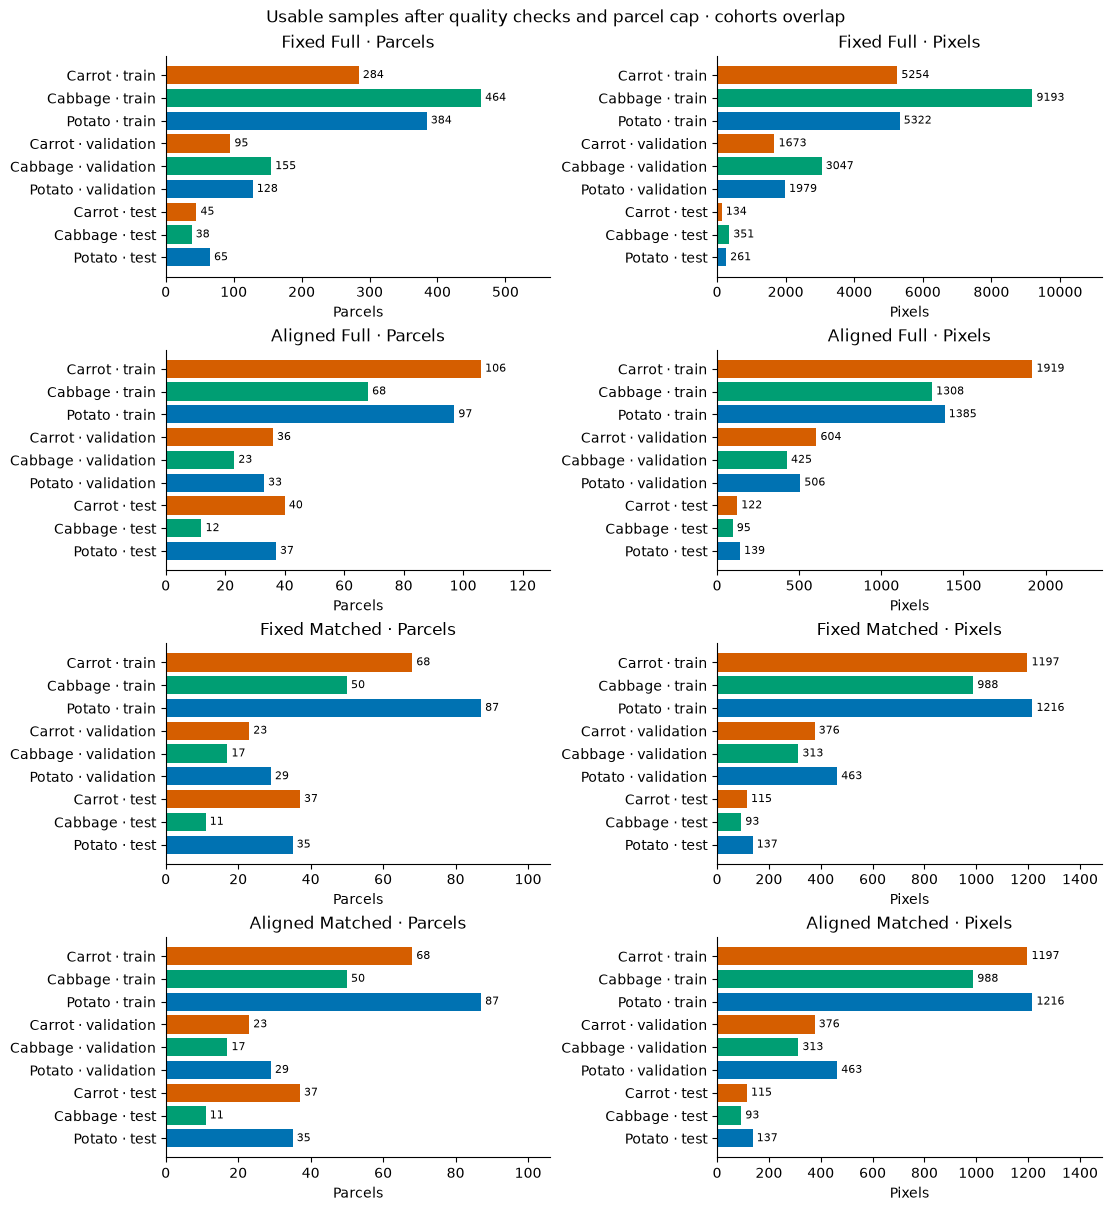

In [4]:
from crop_pipeline.visualization.demo import plot_usable_samples
from IPython.display import display
import matplotlib.pyplot as plt
figure = plot_usable_samples(usable_samples)
display(figure)
plt.close(figure)


## Usable samples against targets

Dashed lines are the per-crop targets: 60 parcels / 1,200 pixels for training and 20 parcels / 400 pixels each for validation and testing. Bars below a line are shortfalls. Reaching a target does not establish accuracy.

Saved figure: ./data/pipeline_work/analysis/external/external_t4tyh93t/figures/usable_vs_targets_fixed_full.png


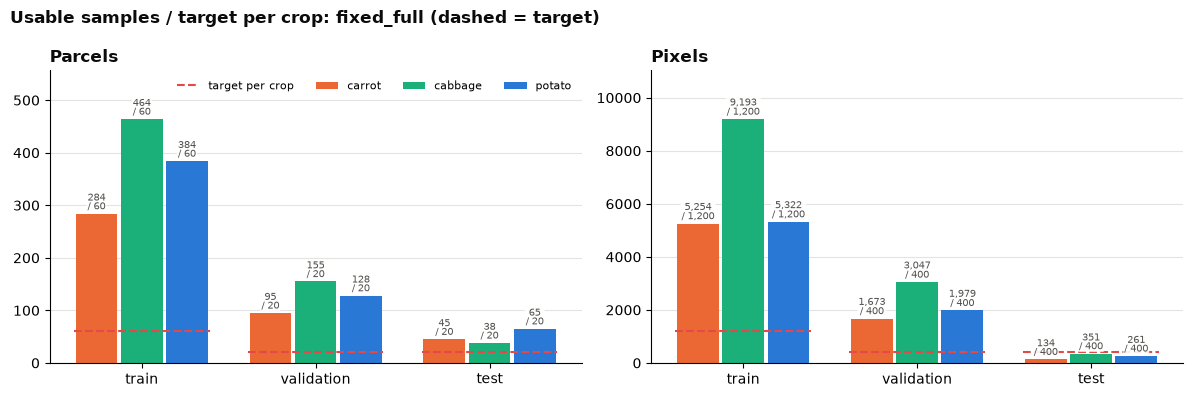

Saved figure: ./data/pipeline_work/analysis/external/external_t4tyh93t/figures/usable_vs_targets_aligned_full.png


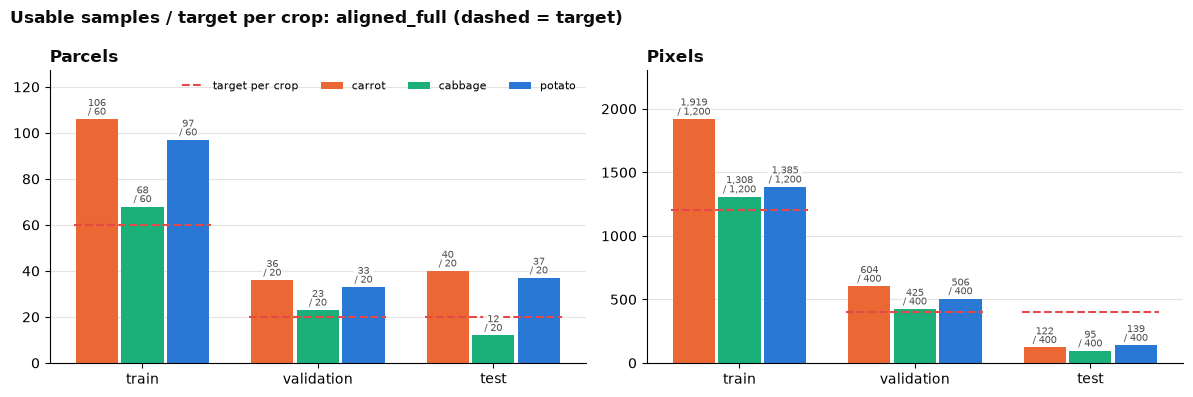

Saved figure: ./data/pipeline_work/analysis/external/external_t4tyh93t/figures/usable_vs_targets_fixed_matched.png


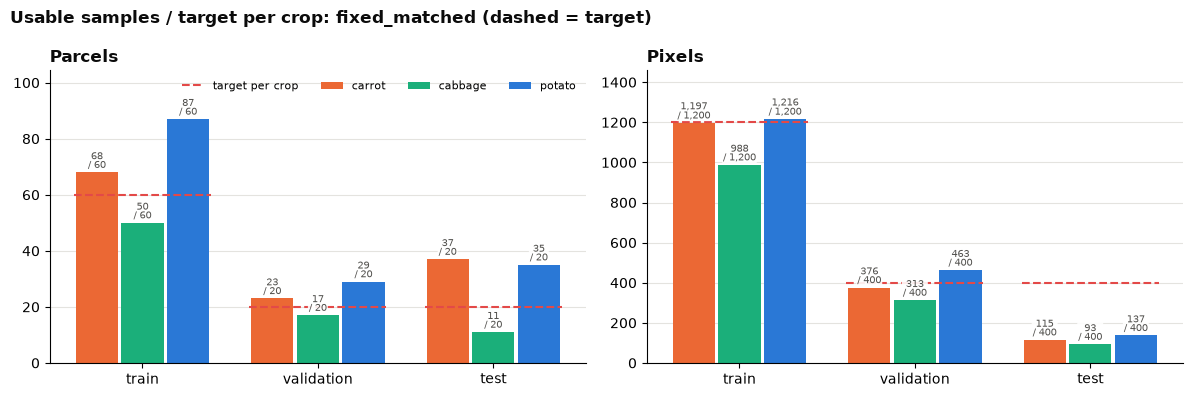

Saved figure: ./data/pipeline_work/analysis/external/external_t4tyh93t/figures/usable_vs_targets_aligned_matched.png


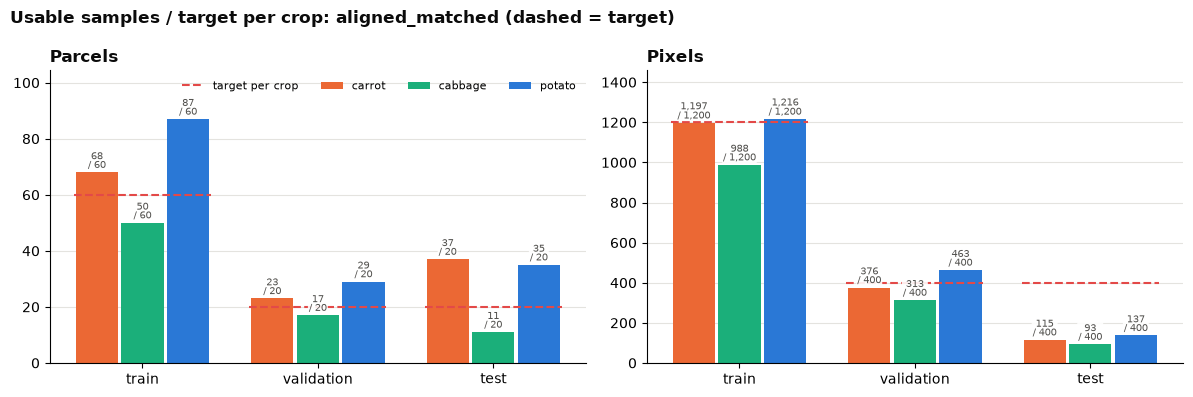

In [5]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
from crop_pipeline.visualization import workflow_figures as figures


def show_and_save(figure, folder, name):
    """Display inline and keep a PNG beside the run outputs for reports and slides."""
    print("Saved figure:", figures.save_figure(figure, folder, name))
    display(figure)
    plt.close(figure)

figure_folder = feature_handoff.parent / "figures"
for cohort in ("fixed_full", "aligned_full", "fixed_matched", "aligned_matched"):
    show_and_save(figures.draw_usable_vs_targets(usable_samples, cohort), figure_folder, f"usable_vs_targets_{cohort}")